In [1]:
!pip install lightly --quiet

import os, json, time, math, random, copy
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision.models import resnet50
from PIL import Image
import matplotlib.pyplot as plt

# Transform (same as SimCLR uses)
from lightly.transforms.simclr_transform import SimCLRTransform

# BYOL-specific
from lightly.loss import NegativeCosineSimilarity
from lightly.models.modules import BYOLProjectionHead, BYOLPredictionHead
from lightly.models.utils import deactivate_requires_grad, update_momentum

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 891.2/891.2 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.6/165.6 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.8/155.8 kB 10.1 MB/s eta 0:00:00
Device: cuda


In [2]:
SPLIT_PATH = "/kaggle/input/notebooks/yeamins/438-assignment-a/split.json"
DATA_ROOT  = "/kaggle/input/datasets/yeamins/ar-plaqsegm1-ultrasound-segmentation/Ar-PlaqSegm1 First Argentine database of B-mode ul"

with open(SPLIT_PATH) as f:
    split = json.load(f)

def fix_paths(records, new_root):
    fixed = []
    for rec in records:
        r = rec.copy()
        for key in ["img_path", "mask_path"]:
            parts = r[key].replace("\\", "/").split("/")
            r[key] = os.path.join(new_root, parts[-2], parts[-1])
        fixed.append(r)
    return fixed

train_records = fix_paths(split["train"], DATA_ROOT)   # unlabeled pretraining
val_records   = fix_paths(split["val"],   DATA_ROOT)   # labeled fine-tuning
test_records  = fix_paths(split["test"],  DATA_ROOT)   # monitoring + final eval
MASK_THRESHOLD = split["mask_threshold"]

print(f"Train (unlabeled): {len(train_records)}")
print(f"Val (labeled):     {len(val_records)}")
print(f"Test (eval):       {len(test_records)}")

Train (unlabeled): 416
Val (labeled):     73
Test (eval):       48


In [3]:
class BYOLPretrainDataset(Dataset):
    def __init__(self, records, transform):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        img = cv2.imread(self.records[idx]["img_path"], cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        img = Image.fromarray(img)
        view1, view2 = self.transform(img)
        return view1, view2

byol_transform = SimCLRTransform(
    input_size=224, cj_prob=0.5, cj_strength=0.3,
    gaussian_blur=0.5, random_gray_scale=0.0
)

pretrain_ds = BYOLPretrainDataset(train_records, byol_transform)
pretrain_loader = DataLoader(
    pretrain_ds, batch_size=64, shuffle=True,
    num_workers=2, drop_last=True, pin_memory=True
)
print(f"Pretrain batches per epoch: {len(pretrain_loader)}")

Pretrain batches per epoch: 6


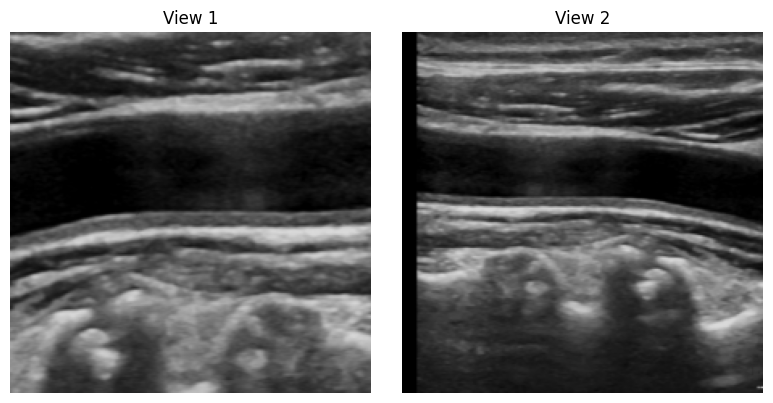

In [4]:
sample_v1, sample_v2 = pretrain_ds[0]

def denorm(t):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return (t * std + mean).clamp(0,1).permute(1,2,0).numpy()

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(denorm(sample_v1)); ax[0].set_title("View 1"); ax[0].axis("off")
ax[1].imshow(denorm(sample_v2)); ax[1].set_title("View 2"); ax[1].axis("off")
plt.tight_layout(); plt.show()

In [5]:
class BYOLModel(nn.Module):
    def __init__(self):
        super().__init__()
        # Online network: encoder + projection + predictor
        backbone = resnet50(weights="IMAGENET1K_V2")
        self.encoder = nn.Sequential(*list(backbone.children())[:-1])
        self.projection = BYOLProjectionHead(2048, 4096, 256)
        self.prediction = BYOLPredictionHead(256, 4096, 256)

        # Target network: EMA copies of encoder + projection (no predictor)
        self.encoder_target    = copy.deepcopy(self.encoder)
        self.projection_target = copy.deepcopy(self.projection)

        # Target network is never updated by gradients
        deactivate_requires_grad(self.encoder_target)
        deactivate_requires_grad(self.projection_target)

    def forward_online(self, x):
        h = self.encoder(x).flatten(1)
        z = self.projection(h)
        p = self.prediction(z)
        return p

    def forward_target(self, x):
        h = self.encoder_target(x).flatten(1)
        z = self.projection_target(h)
        return z.detach()   # stop-gradient — critical for BYOL

model = BYOLModel().to(device)
print(f"Params: {sum(p.numel() for p in model.parameters())/1e6:.1f}M")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 147MB/s]


Params: 68.0M


In [6]:
PRETRAIN_CONFIG = {
    "epochs": 50,
    "batch_size": 64,
    "lr": 3e-4,
    "weight_decay": 1e-6,
    "ema_decay_base": 0.996,   # τ in the BYOL paper — starts at 0.996
    "ema_decay_final": 1.0,    # ramps to 1.0 with cosine schedule
    "optimizer": "AdamW",
    "loss": "symmetric negative cosine similarity",
}

criterion = NegativeCosineSimilarity()
optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=PRETRAIN_CONFIG["lr"],
    weight_decay=PRETRAIN_CONFIG["weight_decay"]
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=PRETRAIN_CONFIG["epochs"]
)

def ema_decay_at(epoch, total_epochs, base=0.996):
    # cosine ramp from base to 1.0 (BYOL paper Eq. 1)
    return 1 - (1 - base) * (math.cos(math.pi * epoch / total_epochs) + 1) / 2

pretrain_losses = []
epoch_times = []
model.train()

for epoch in range(PRETRAIN_CONFIG["epochs"]):
    t0 = time.time()
    epoch_loss = 0.0
    tau = ema_decay_at(epoch, PRETRAIN_CONFIG["epochs"], PRETRAIN_CONFIG["ema_decay_base"])

    for view1, view2 in pretrain_loader:
        view1, view2 = view1.to(device), view2.to(device)

        # Online predictions
        p1 = model.forward_online(view1)
        p2 = model.forward_online(view2)
        # Target projections (with stop-gradient)
        z1 = model.forward_target(view1)
        z2 = model.forward_target(view2)

        # Symmetric loss
        loss = 0.5 * (criterion(p1, z2) + criterion(p2, z1))

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # EMA update — target moves slowly toward online
        update_momentum(model.encoder,    model.encoder_target,    m=tau)
        update_momentum(model.projection, model.projection_target, m=tau)

        epoch_loss += loss.item()

    scheduler.step()
    avg_loss = epoch_loss / len(pretrain_loader)
    dt = time.time() - t0
    pretrain_losses.append(avg_loss); epoch_times.append(dt)
    print(f"Epoch {epoch+1:02d}/50 | loss: {avg_loss:.4f} | τ: {tau:.4f} | {dt:.1f}s")

# Save encoder only (drop projection, prediction, and target networks)
torch.save(model.encoder.state_dict(), "/kaggle/working/byol_encoder.pt")
print(f"\nMean epoch time: {np.mean(epoch_times):.1f}s")
print(f"Total pretrain time: {sum(epoch_times)/60:.1f} min")

Epoch 01/50 | loss: -0.4208 | τ: 0.9960 | 13.3s
Epoch 02/50 | loss: -0.5777 | τ: 0.9960 | 11.0s
Epoch 03/50 | loss: -0.5917 | τ: 0.9960 | 11.1s
Epoch 04/50 | loss: -0.5994 | τ: 0.9960 | 11.1s
Epoch 05/50 | loss: -0.6002 | τ: 0.9961 | 11.4s
Epoch 06/50 | loss: -0.6008 | τ: 0.9961 | 11.7s
Epoch 07/50 | loss: -0.6016 | τ: 0.9961 | 11.7s
Epoch 08/50 | loss: -0.6024 | τ: 0.9962 | 12.0s
Epoch 09/50 | loss: -0.6003 | τ: 0.9962 | 12.2s
Epoch 10/50 | loss: -0.5942 | τ: 0.9963 | 12.4s
Epoch 11/50 | loss: -0.5971 | τ: 0.9964 | 12.6s
Epoch 12/50 | loss: -0.5982 | τ: 0.9965 | 12.9s
Epoch 13/50 | loss: -0.5937 | τ: 0.9965 | 12.8s
Epoch 14/50 | loss: -0.6016 | τ: 0.9966 | 13.0s
Epoch 15/50 | loss: -0.5974 | τ: 0.9967 | 13.2s
Epoch 16/50 | loss: -0.5955 | τ: 0.9968 | 13.7s
Epoch 17/50 | loss: -0.5985 | τ: 0.9969 | 13.7s
Epoch 18/50 | loss: -0.5973 | τ: 0.9970 | 13.7s
Epoch 19/50 | loss: -0.5999 | τ: 0.9971 | 13.8s
Epoch 20/50 | loss: -0.6030 | τ: 0.9973 | 13.7s
Epoch 21/50 | loss: -0.6074 | τ: 0.9974 

In [7]:
class ResNetEncoder(nn.Module):
    """Returns multi-scale features from ResNet-50."""
    def __init__(self, pretrained_path):
        super().__init__()
        backbone = resnet50(weights=None)
        sd = torch.load(pretrained_path, map_location="cpu")
        backbone_sd = {}
        keys = list(backbone.state_dict().keys())
        vals = list(sd.values())
        for k, v in zip(keys, vals):
            backbone_sd[k] = v
        backbone.load_state_dict(backbone_sd, strict=False)

        self.stem   = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool)
        self.layer1 = backbone.layer1   # C2:  256 ch, /4
        self.layer2 = backbone.layer2   # C3:  512 ch, /8
        self.layer3 = backbone.layer3   # C4: 1024 ch, /16
        self.layer4 = backbone.layer4   # C5: 2048 ch, /32

    def forward(self, x):
        x  = self.stem(x)
        c2 = self.layer1(x)
        c3 = self.layer2(c2)
        c4 = self.layer3(c3)
        c5 = self.layer4(c4)
        return c3, c4, c5

class MultiScaleDecoder(nn.Module):
    """FPN-style upsampling decoder producing per-pixel logits."""
    def __init__(self, num_classes=2):
        super().__init__()
        self.reduce5 = nn.Conv2d(2048, 256, 1)
        self.reduce4 = nn.Conv2d(1024, 256, 1)
        self.reduce3 = nn.Conv2d(512,  256, 1)

        self.fuse4 = nn.Conv2d(256, 256, 3, padding=1)
        self.fuse3 = nn.Conv2d(256, 256, 3, padding=1)

        self.head = nn.Sequential(
            nn.Conv2d(256, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, num_classes, 1),
        )

    def forward(self, c3, c4, c5, out_size):
        p5 = self.reduce5(c5)
        p4 = self.reduce4(c4) + F.interpolate(p5, size=c4.shape[-2:], mode="bilinear", align_corners=False)
        p4 = self.fuse4(p4)
        p3 = self.reduce3(c3) + F.interpolate(p4, size=c3.shape[-2:], mode="bilinear", align_corners=False)
        p3 = self.fuse3(p3)
        logits = self.head(p3)
        logits = F.interpolate(logits, size=out_size, mode="bilinear", align_corners=False)
        return logits

class SegModel(nn.Module):
    def __init__(self, encoder_path, num_classes=2):
        super().__init__()
        self.encoder = ResNetEncoder(encoder_path)
        self.decoder = MultiScaleDecoder(num_classes)

    def forward(self, x):
        H, W = x.shape[-2:]
        c3, c4, c5 = self.encoder(x)
        return self.decoder(c3, c4, c5, (H, W))

In [8]:
IMG_SIZE = 512

class SegDataset(Dataset):
    def __init__(self, records, augment=False):
        self.records = records
        self.augment = augment
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
        self.std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        img = cv2.imread(rec["img_path"], cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        mask = cv2.imread(rec["mask_path"], cv2.IMREAD_GRAYSCALE)
        mask = (mask > MASK_THRESHOLD).astype(np.int64)

        img  = cv2.resize(img,  (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)

        if self.augment and random.random() < 0.5:
            img = np.fliplr(img).copy(); mask = np.fliplr(mask).copy()

        img_t = torch.from_numpy(img).permute(2,0,1).float() / 255.0
        img_t = (img_t - self.mean) / self.std
        mask_t = torch.from_numpy(mask).long()
        return img_t, mask_t, rec["idx"]

finetune_loader = DataLoader(
    SegDataset(val_records, augment=True),
    batch_size=8, shuffle=True, num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    SegDataset(test_records, augment=False),
    batch_size=8, shuffle=False, num_workers=2, pin_memory=True
)
print(f"Fine-tune batches: {len(finetune_loader)} | Test batches: {len(test_loader)}")

Fine-tune batches: 10 | Test batches: 6


In [9]:
def compute_metrics(pred, gt, num_classes=2):
    conf = np.zeros((num_classes, num_classes), dtype=np.int64)
    for g in range(num_classes):
        for p in range(num_classes):
            conf[g, p] = int(((gt == g) & (pred == p)).sum())

    iou_per_class, dice_per_class = [], []
    for c in range(num_classes):
        tp = conf[c, c]
        fn = conf[c, :].sum() - tp
        fp = conf[:, c].sum() - tp
        iou  = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else float("nan")
        dice = 2*tp / (2*tp + fp + fn) if (2*tp + fp + fn) > 0 else float("nan")
        iou_per_class.append(iou); dice_per_class.append(dice)

    overall_acc = float(np.diag(conf).sum() / conf.sum()) if conf.sum() > 0 else 0.0
    per_class_acc = [conf[c,c]/conf[c,:].sum() if conf[c,:].sum() > 0 else float("nan")
                     for c in range(num_classes)]
    return {
        "mIoU": float(np.nanmean(iou_per_class)),
        "iou_per_class": iou_per_class,
        "mean_dice": float(np.nanmean(dice_per_class)),
        "dice_per_class": dice_per_class,
        "overall_pixel_acc": overall_acc,
        "mean_pixel_acc": float(np.nanmean(per_class_acc)),
        "per_class_acc": per_class_acc,
        "confusion_matrix": conf.tolist(),
    }

def evaluate(model, loader):
    model.eval()
    conf_total = np.zeros((2, 2), dtype=np.int64)
    per_image = []
    with torch.no_grad():
        for imgs, masks, idxs in loader:
            imgs = imgs.to(device)
            logits = model(imgs)
            preds = logits.argmax(1).cpu().numpy()
            gts = masks.numpy()
            for i in range(len(preds)):
                m = compute_metrics(preds[i], gts[i])
                m["idx"] = idxs[i] if isinstance(idxs[i], str) else str(idxs[i].item())
                m["plaque_iou"] = m["iou_per_class"][1]
                m["has_plaque"] = int(gts[i].sum() > 0)
                per_image.append(m)
                conf_total += np.array(m["confusion_matrix"])
    conf = conf_total
    iou  = [conf[c,c] / max(conf[c,:].sum()+conf[:,c].sum()-conf[c,c], 1) for c in range(2)]
    dice = [2*conf[c,c] / max(2*conf[c,c] + (conf[c,:].sum()-conf[c,c]) + (conf[:,c].sum()-conf[c,c]), 1) for c in range(2)]
    overall = {
        "confusion_matrix": conf.tolist(),
        "mIoU": float(np.mean(iou)),
        "iou_per_class": iou,
        "mean_dice": float(np.mean(dice)),
        "dice_per_class": dice,
        "overall_pixel_acc": float(np.diag(conf).sum()/conf.sum()),
    }
    return overall, per_image

In [10]:
FINETUNE_CONFIG = {
    "epochs": 50,
    "batch_size": 8,
    "encoder_lr": 1e-5,
    "decoder_lr": 1e-4,
    "weight_decay": 1e-4,
    "loss": "CE + Dice",
    "frozen_or_finetuned": "fine-tuned",
    "input_resolution": IMG_SIZE,
}

seg_model = SegModel("/kaggle/working/byol_encoder.pt", num_classes=2).to(device)

optimizer = torch.optim.AdamW([
    {"params": seg_model.encoder.parameters(), "lr": FINETUNE_CONFIG["encoder_lr"]},
    {"params": seg_model.decoder.parameters(), "lr": FINETUNE_CONFIG["decoder_lr"]},
], weight_decay=FINETUNE_CONFIG["weight_decay"])

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FINETUNE_CONFIG["epochs"])

def dice_loss(logits, target, smooth=1.0):
    probs = F.softmax(logits, dim=1)
    target_1h = F.one_hot(target, num_classes=2).permute(0,3,1,2).float()
    intersect = (probs * target_1h).sum(dim=(2,3))
    union = probs.sum(dim=(2,3)) + target_1h.sum(dim=(2,3))
    return 1 - ((2 * intersect + smooth) / (union + smooth)).mean()

ce_loss = nn.CrossEntropyLoss()

train_losses, test_mious, epoch_times_ft = [], [], []
best_miou = 0.0
best_state = None
best_epoch = 0

for epoch in range(FINETUNE_CONFIG["epochs"]):
    t0 = time.time()
    seg_model.train()
    epoch_loss = 0.0

    for imgs, masks, _ in finetune_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        logits = seg_model(imgs)
        loss = ce_loss(logits, masks) + dice_loss(logits, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    scheduler.step()
    avg_loss = epoch_loss / len(finetune_loader)

    test_overall, _ = evaluate(seg_model, test_loader)
    dt = time.time() - t0

    train_losses.append(avg_loss)
    test_mious.append(test_overall["mIoU"])
    epoch_times_ft.append(dt)

    if test_overall["mIoU"] > best_miou:
        best_miou = test_overall["mIoU"]
        best_state = {k: v.cpu().clone() for k, v in seg_model.state_dict().items()}
        best_epoch = epoch + 1

    print(f"Epoch {epoch+1:02d}/50 | loss={avg_loss:.4f} | test mIoU={test_overall['mIoU']:.4f} | {dt:.1f}s")

print(f"\nBest test mIoU: {best_miou:.4f} at epoch {best_epoch}")
torch.save(best_state, "/kaggle/working/byol_seg_best.pt")

Epoch 01/50 | loss=1.3675 | test mIoU=0.3347 | 7.6s
Epoch 02/50 | loss=1.0067 | test mIoU=0.5395 | 6.9s
Epoch 03/50 | loss=0.8345 | test mIoU=0.5710 | 7.1s
Epoch 04/50 | loss=0.7673 | test mIoU=0.6050 | 7.1s
Epoch 05/50 | loss=0.7316 | test mIoU=0.6028 | 7.1s
Epoch 06/50 | loss=0.7091 | test mIoU=0.6173 | 7.1s
Epoch 07/50 | loss=0.6879 | test mIoU=0.6000 | 7.0s
Epoch 08/50 | loss=0.6811 | test mIoU=0.6420 | 7.1s
Epoch 09/50 | loss=0.6676 | test mIoU=0.6304 | 7.0s
Epoch 10/50 | loss=0.6444 | test mIoU=0.6235 | 7.0s
Epoch 11/50 | loss=0.6424 | test mIoU=0.6308 | 7.1s
Epoch 12/50 | loss=0.6297 | test mIoU=0.6368 | 7.0s
Epoch 13/50 | loss=0.6199 | test mIoU=0.6477 | 7.0s
Epoch 14/50 | loss=0.6114 | test mIoU=0.6393 | 7.1s
Epoch 15/50 | loss=0.6033 | test mIoU=0.6402 | 7.0s
Epoch 16/50 | loss=0.5878 | test mIoU=0.6361 | 7.0s
Epoch 17/50 | loss=0.5892 | test mIoU=0.6507 | 7.1s
Epoch 18/50 | loss=0.5727 | test mIoU=0.6297 | 7.1s
Epoch 19/50 | loss=0.5665 | test mIoU=0.6499 | 7.0s
Epoch 20/50 

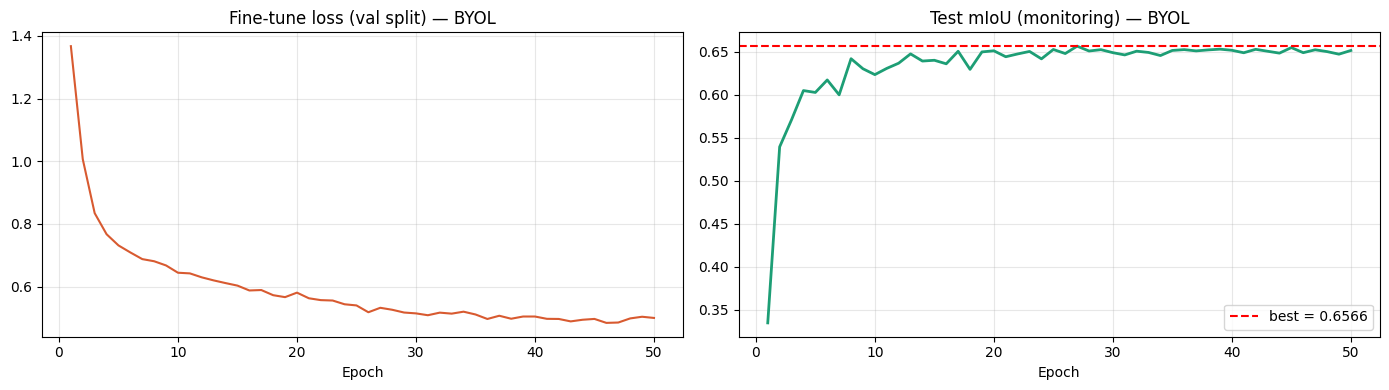

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(range(1, 51), train_losses, color="#D85A30")
axes[0].set_title("Fine-tune loss (val split) — BYOL")
axes[0].set_xlabel("Epoch"); axes[0].grid(alpha=0.3)

axes[1].plot(range(1, 51), test_mious, color="#1D9E75", linewidth=2)
axes[1].axhline(best_miou, color="red", linestyle="--", label=f"best = {best_miou:.4f}")
axes[1].set_title("Test mIoU (monitoring) — BYOL")
axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/byol_finetune_curves.png", dpi=150)
plt.show()

In [12]:
seg_model.load_state_dict(torch.load("/kaggle/working/byol_seg_best.pt"))
final_overall, final_per_image = evaluate(seg_model, test_loader)

print(f"Test mIoU:       {final_overall['mIoU']:.4f}")
print(f"IoU background:  {final_overall['iou_per_class'][0]:.4f}")
print(f"IoU plaque:      {final_overall['iou_per_class'][1]:.4f}")
print(f"Mean Dice:       {final_overall['mean_dice']:.4f}")
print(f"Dice plaque:     {final_overall['dice_per_class'][1]:.4f}")
print(f"Pixel accuracy:  {final_overall['overall_pixel_acc']:.4f}")

Test mIoU:       0.6566
IoU background:  0.9916
IoU plaque:      0.3216
Mean Dice:       0.7413
Dice plaque:     0.4867
Pixel accuracy:  0.9917


Worst 10 by plaque IoU:
    idx  plaque_iou  has_plaque
22  520    0.000000           1
23  521    0.000000           1
25  523    0.000000           1
42  540    0.057944           1
40  538    0.125678           1
44  542    0.152342           1
45  543    0.173103           1
27  525    0.174213           1
37  535    0.226119           1
43  541    0.250963           1


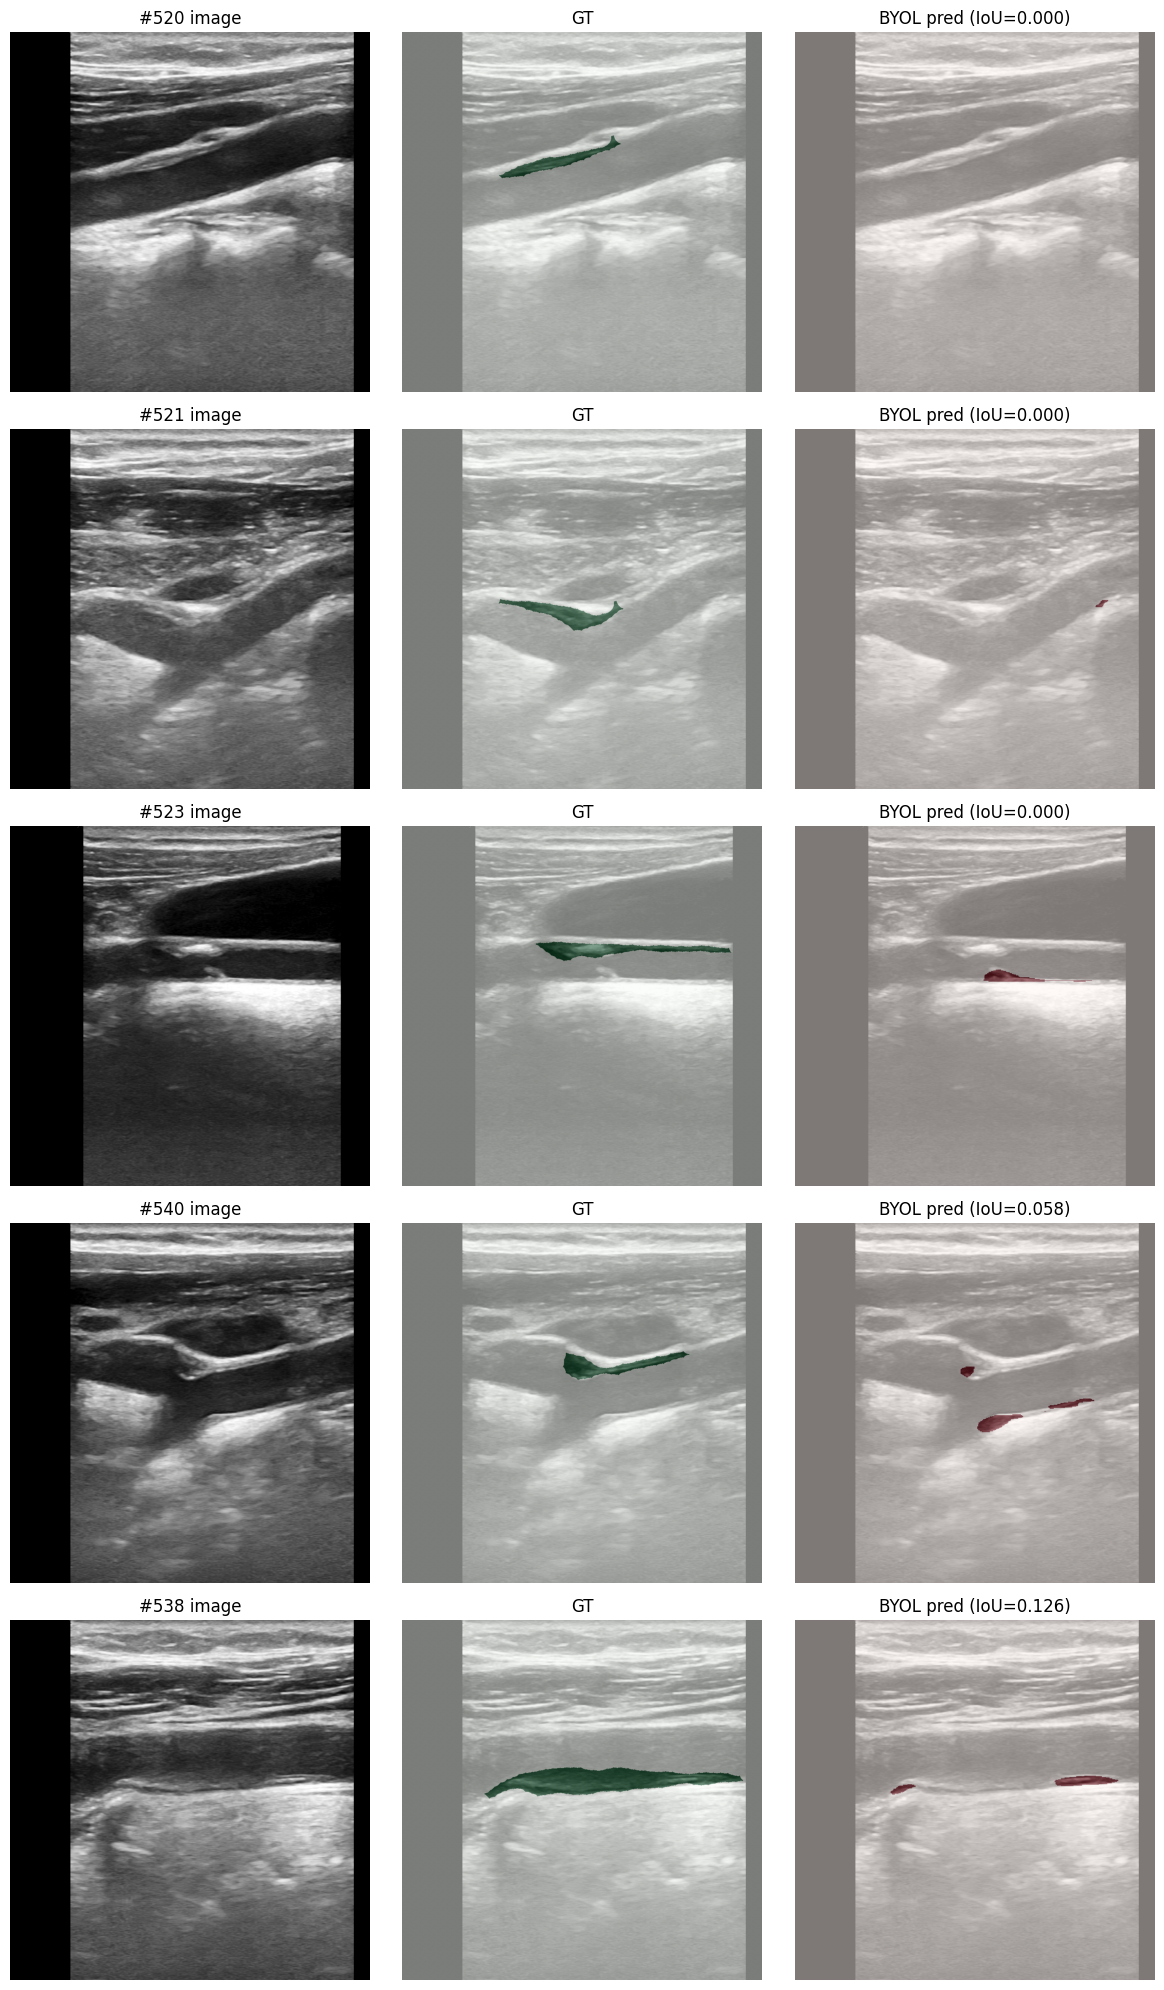

In [13]:
per_img_df = pd.DataFrame([{
    "idx": r["idx"],
    "plaque_iou": r["plaque_iou"],
    "has_plaque": r["has_plaque"]
} for r in final_per_image])

positive = per_img_df[per_img_df["has_plaque"] == 1]
worst10 = positive.nsmallest(10, "plaque_iou")
print("Worst 10 by plaque IoU:"); print(worst10)

per_img_df.to_csv("/kaggle/working/byol_per_image.csv", index=False)

worst5_idx = worst10["idx"].tolist()[:5]
fig, axes = plt.subplots(5, 3, figsize=(12, 20))
for row, idx in enumerate(worst5_idx):
    rec = next(r for r in test_records if str(r["idx"]) == str(idx))
    img = cv2.imread(rec["img_path"], cv2.IMREAD_GRAYSCALE)
    gt = (cv2.imread(rec["mask_path"], cv2.IMREAD_GRAYSCALE) > MASK_THRESHOLD).astype(np.uint8)

    img_t = torch.from_numpy(cv2.cvtColor(cv2.resize(img, (IMG_SIZE, IMG_SIZE)), cv2.COLOR_GRAY2RGB))
    img_t = (img_t.permute(2,0,1).float()/255.0 - torch.tensor([0.485,0.456,0.406]).view(3,1,1)) / torch.tensor([0.229,0.224,0.225]).view(3,1,1)
    seg_model.eval()
    with torch.no_grad():
        pred = seg_model(img_t.unsqueeze(0).to(device)).argmax(1)[0].cpu().numpy()
    pred = cv2.resize(pred.astype(np.uint8), (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)

    axes[row,0].imshow(img, cmap="gray"); axes[row,0].set_title(f"#{idx} image"); axes[row,0].axis("off")
    axes[row,1].imshow(img, cmap="gray"); axes[row,1].imshow(gt, cmap="Greens", alpha=0.5); axes[row,1].set_title("GT"); axes[row,1].axis("off")
    axes[row,2].imshow(img, cmap="gray"); axes[row,2].imshow(pred, cmap="Reds", alpha=0.5); axes[row,2].set_title(f"BYOL pred (IoU={worst10.iloc[row]['plaque_iou']:.3f})"); axes[row,2].axis("off")
plt.tight_layout()
plt.savefig("/kaggle/working/byol_worst_cases.png", dpi=100)
plt.show()

In [14]:
results = {
    "model": "BYOL (ResNet-50) + YOLOv26-style decoder",
    "ssl_method": "BYOL",
    "backbone": "ResNet-50",
    "pretrain_source": "ImageNet-pretrained + SSL fine-tuned on train split",
    "pretrain_epochs": 50,
    "pretrain_ema_decay_base": 0.996,
    "pretrain_mean_epoch_sec": float(np.mean(epoch_times[:50])),
    "pretrain_total_min": float(sum(epoch_times[:50])/60),
    "finetune_epochs": 50,
    "frozen_or_finetuned": "fine-tuned",
    "best_epoch": best_epoch,
    "labeled_images_used": len(val_records),
    "test_metrics": final_overall,
    "per_image_results": [
        {"idx": r["idx"], "plaque_iou": r["plaque_iou"], "has_plaque": r["has_plaque"]}
        for r in final_per_image
    ],
}

with open("/kaggle/working/results_byol.json", "w") as f:
    json.dump(results, f, indent=2)

print("Saved results_byol.json")

Saved results_byol.json
